# L14 -  Quantisierung der Filterkoeffizienten 

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l14.m).

Benoetigte `m`-Dateien:  [`lfxquant.m`](./lfxquant.m), [`lcoefrnd.m`](./lcoefrnd.m), [`lcascade.m `](./lcascade.m)

## Teilaufgabe a:  Cauer Tiefpass

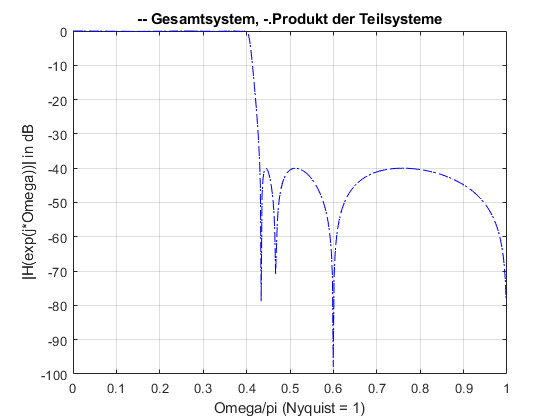

In [2]:
% #####  Teilaufgabe a:  Cauer Tiefpass  #####
[b,a] = ellip(7, 0.1, 40, 0.4);
[H,W] = freqz(b,a,512);

% # grafische Ausgabe # %
figure; 
plot(W/pi,20*log10(abs(H))); 
grid; 
xlabel('Omega/pi (Nyquist = 1)'); 
ylabel('|H(exp(j*Omega))| in dB'); 
title('Cauer-TP');

## Teilaufgabe b:  Filterkoeffizienten quantisieren

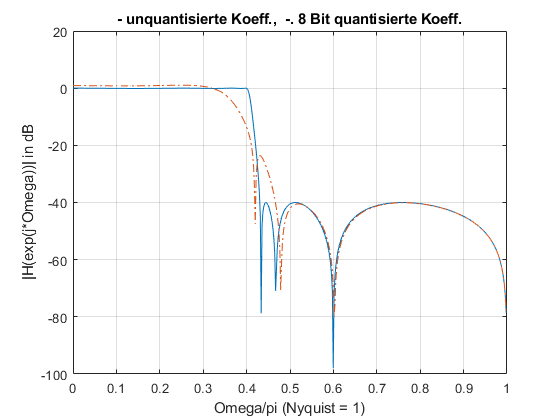

In [1]:
% #####  Teilaufgabe b:  Filterkoeffizienten quantisieren  #####
[b,a] = ellip(7, 0.1, 40, 0.4);
[H,W] = freqz(b,a,512);
[bq,nb] = lcoefrnd(b,8);
[aq,na] = lcoefrnd(a,8);
Hq = nb/na*freqz(bq,aq,512);

% # grafische Ausgabe # %
figure; 
plot(W/pi,20*log10(abs(H))); 
hold on; 
plot(W/pi,20*log10(abs(Hq)),'-.'); 
hold off; 
grid; 
title('- unquantisierte Koeff.,  -. 8 Bit quantisierte Koeff.'); 
xlabel('Omega/pi (Nyquist = 1)');
ylabel('|H(exp(j*Omega))| in dB');

## Teilaufgabe c:  minimale Wortlaenge bestimmen

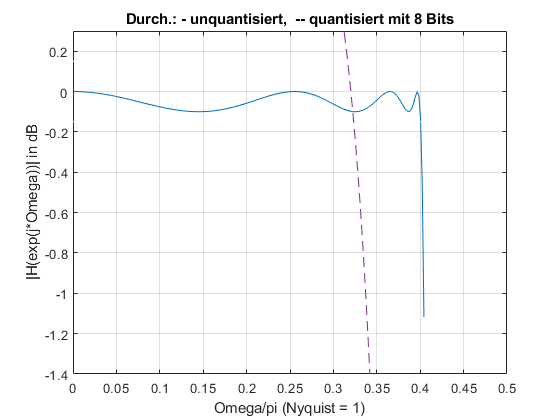

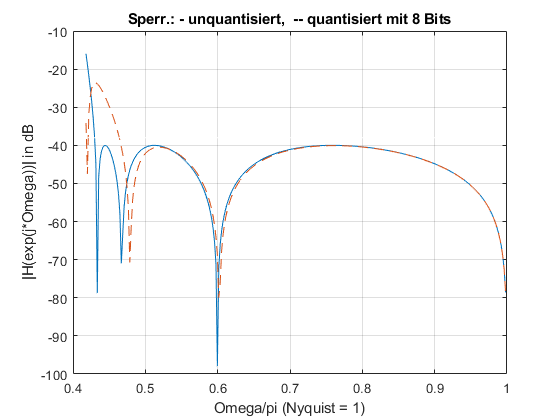

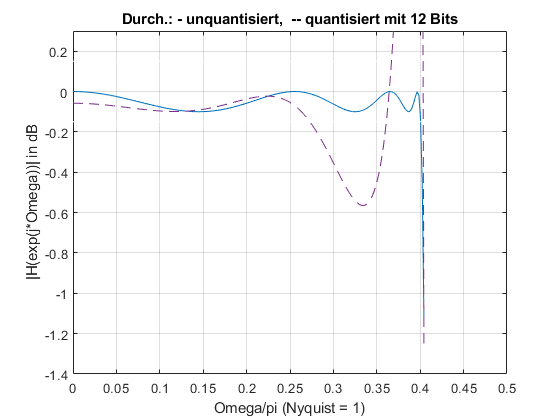

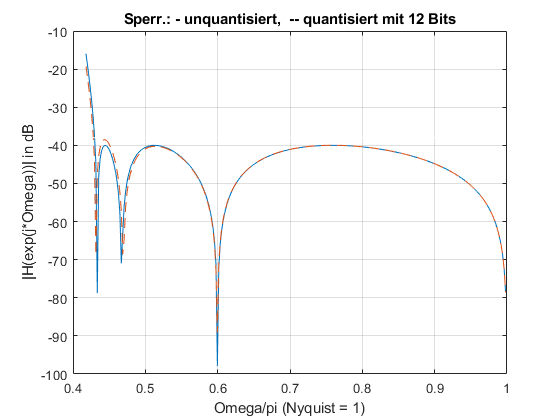

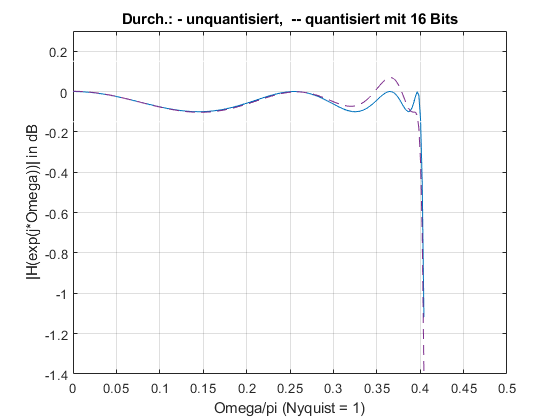

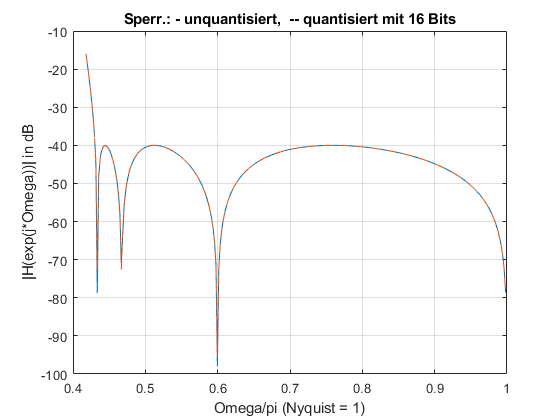

In [3]:
[b,a] = ellip(7,0.1,40,0.4);   % Filter entwerfen
[H,W] = freqz(b,a,512);        % unquantisierte Uebertragungsfunktion
v_laenge = [8,12,16];

for l=v_laenge
    [bq,nb] = lcoefrnd(b,l);     % Koeffizienten mit l Bits quantisieren
    [aq,na] = lcoefrnd(a,l);
    Hq = nb/na*freqz(bq,aq,512); % quantisierte Uebertragungsfunktion
    
    % # grafische Ausgabe # %
    % Durchlassbereich
    figure;                      
    plot(W(1:208)/pi,20*log10(abs(H(1:208)))); 
    axis([0 0.5 -1.4 0.3]); 
    grid; 
    hold on;
    plot(W(1:208)/pi,-0.15*ones(size(Hq(1:208))),'w' ); %Toleranzgrenzen darstellen
    plot(W(1:208)/pi,+0.15*ones(size(Hq(1:208))),'w' );
    plot(W(1:208)/pi,20*log10(abs(Hq(1:208))),'--'); 
    hold off;
    xlabel('Omega/pi (Nyquist = 1)');
    ylabel('|H(exp(j*Omega))| in dB');
    string = sprintf('Durch.: - unquantisiert,  -- quantisiert mit %d Bits', l);
    title(string);
    
    % Sperrbereich
    figure;                      
    plot(W(215:512)/pi,20*log10(abs(H(215:512)))); 
    hold on;
    plot(W(215:512)/pi,20*log10(abs(Hq(215:512))),'--');
    plot(W(215:512)/pi,-38*ones(size(Hq(215:512))),'w' ); 
    grid;
    hold off; 
    xlabel('Omega/pi (Nyquist = 1)'); 
    ylabel('|H(exp(j*Omega))| in dB');
    string = sprintf('Sperr.: - unquantisiert,  -- quantisiert mit %d Bits', l);
    title(string);
end

## Teilaufgabe d:  Filterkoeffizienten quantisieren

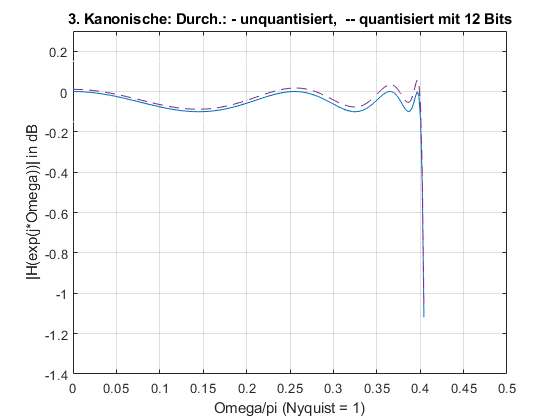

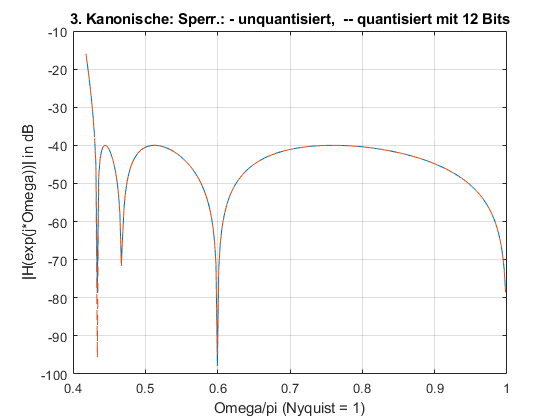

In [2]:
[b,a] = ellip(7,0.1,40,0.4);  % Filter entwerfen
[B,A] = lcascade(b,a);        % unquantisierte Uebertragungsfunktion in
                              % 3-ter kanonischer Form berechnen
[m,n] = size(B);              % Produkt der Uebertragungsfunkt. der Teilsysteme
Hi = zeros(512,m);

for k = 1:m
    Hi(:,k) = freqz(B(k,:),A(k,:),512);
end
H3k = Hi(:,1) .* Hi(:,2) .* Hi(:,3) .* Hi(:,4);
Bq = zeros(size(B));          % Vektoren initialisieren
Aq = Bq;
nb = zeros(m,1);
na = nb;
v_laenge=12;

for l=v_laenge

    for k = 1:m         % Koeffizienten der Teilsysteme mit l Bits quantisieren
        [Bq(k,:),nb(k)] = lcoefrnd(B(k,:),l);
        [Aq(k,:),na(k)] = lcoefrnd(A(k,:),l);
    end
    Hq = zeros(512,m);          % quantisierte Gesamtuebertragungsfunktion

    for k=1:m
        Hq(:,k) = nb(k)/na(k)*freqz(Bq(k,:),Aq(k,:),512);
    end
    Hqg = Hq(:,1) .* Hq(:,2) .* Hq(:,3) .* Hq(:,4);

    % # grafische Ausgabe # %
    % Durchlassbereich
    figure;                     
    plot(W(1:208)/pi,20*log10(abs(H3k(1:208))));
    axis([0 0.5 -1.4 0.3]); 
    grid; 
    hold on;
    %Toleranzgrenzen darstellen
    plot(W(1:208)/pi,-0.15*ones(size(Hqg(1:208))),'w' ); 
    plot(W(1:208)/pi,+0.15*ones(size(Hqg(1:208))),'w' );
    plot(W(1:208)/pi,20*log10(abs(Hqg(1:208))),'--'); 
    hold off;
    xlabel('Omega/pi (Nyquist = 1)'); 
    ylabel('|H(exp(j*Omega))| in dB');
    string = sprintf('3. Kanonische: Durch.: - unquantisiert,  -- quantisiert mit %d Bits', l);
    title(string);
    
    % Sperrbereich
    figure;                     
    plot(W(215:512)/pi,20*log10(abs(H3k(215:512)))); 
    hold on;
    plot(W(215:512)/pi,20*log10(abs(Hqg(215:512))),'--');
    plot(W(215:512)/pi,-38*ones(size(Hqg(215:512))),'w' ); 
    grid; 
    hold off;
    xlabel('Omega/pi (Nyquist = 1)'); 
    ylabel('|H(exp(j*Omega))| in dB');
    string = sprintf('3. Kanonische: Sperr.: - unquantisiert,  -- quantisiert mit %d Bits', l);
    title(string);
end
% #####  EOF  #####